In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import HTML
from base64 import b64encode

print("OpenCV version:", cv2.__version__)

OpenCV version: 4.14.0


In [2]:
#uploading a shaky video, or any video which can create outliers in data points
uploaded = files.upload()
VIDEO_PATH = list(uploaded.keys())[0]
print("Using:", VIDEO_PATH)

Saving sample_video.mp4 to sample_video.mp4
Using: sample_video.mp4


In [3]:
#reading the frames
MAX_WIDTH = 640     # downscale for speed
MAX_FRAMES = 300    # cap length so memory stays small

cap = cv2.VideoCapture(VIDEO_PATH)
fps = cap.get(cv2.CAP_PROP_FPS)
orig_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
orig_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"Original: {orig_w}x{orig_h}, {fps:.1f} fps, {total} frames")

scale = min(1.0, MAX_WIDTH / orig_w)
frames = []
while len(frames) < MAX_FRAMES:
    ok, frame = cap.read()
    if not ok:
        break
    if scale < 1.0:
        frame = cv2.resize(frame, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    frames.append(frame)
cap.release()

h, w = frames[0].shape[:2]
print(f"Loaded {len(frames)} frames at {w}x{h}")

Original: 1920x1080, 55.3 fps, 886 frames
Loaded 300 frames at 640x360


VideoCapture reads the video one frame at a time. We print its properties, then load up to 300 frames into a Python list. If the video is wider than 640 px, each frame is downscaled with INTER_AREA, which is the best interpolation for shrinking. Smaller frames make feature tracking much faster, and stabilization doesn't need full resolution. We keep the frames in memory because we'll need them twice: once to estimate motion and once to warp them.

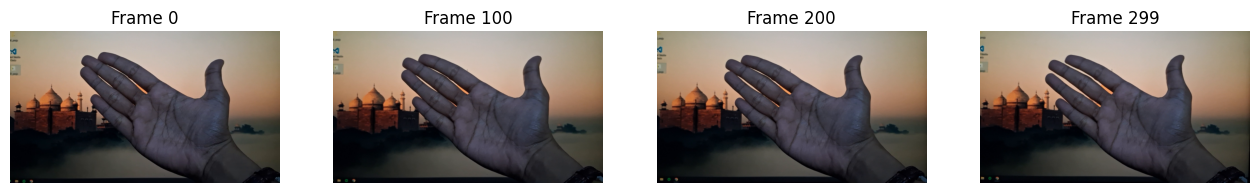

In [4]:
# sanity-check; checking few frames
idx = [0, len(frames)//3, 2*len(frames)//3, len(frames)-1]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, i in zip(axes, idx):
    ax.imshow(cv2.cvtColor(frames[i], cv2.COLOR_BGR2RGB))
    ax.set_title(f"Frame {i}")
    ax.axis("off")
plt.show()

It shows four frames spread across the clip. OpenCV stores images as BGR, while matplotlib expects RGB, so we convert with cvtColor. This is a sanity check that the video loaded correctly and that the scene has enough texture (corners, edges) to track. A blank wall or plain sky would give the feature detector nothing to work with.

In [5]:
# Motion estimation between two frames
FEATURE_PARAMS = dict(maxCorners=400, qualityLevel=0.01, minDistance=20, blockSize=3)
LK_PARAMS = dict(winSize=(21, 21), maxLevel=3,
                 criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))
RANSAC_THRESH = 3.0   # pixels

def estimate_motion(prev_gray, curr_gray):
    # 1. Find good corners to track in the previous frame
    prev_pts = cv2.goodFeaturesToTrack(prev_gray, **FEATURE_PARAMS)
    if prev_pts is None:
        return None

    # 2. Track those corners into the current frame (Lucas-Kanade optical flow)
    curr_pts, status, _ = cv2.calcOpticalFlowPyrLK(prev_gray, curr_gray, prev_pts, None, **LK_PARAMS)
    good = status.flatten() == 1
    p0, p1 = prev_pts[good], curr_pts[good]
    if len(p0) < 10:
        return None

    # 3. Fit a similarity transform to the point pairs, robustly, with RANSAC
    M, inliers = cv2.estimateAffinePartial2D(
        p0, p1, method=cv2.RANSAC,
        ransacReprojThreshold=RANSAC_THRESH, maxIters=2000, confidence=0.99)
    if M is None:
        return None

    dx, dy = M[0, 2], M[1, 2]
    da = np.arctan2(M[1, 0], M[0, 0])      # rotation angle in radians
    inlier_ratio = inliers.sum() / len(inliers)
    return dx, dy, da, inlier_ratio

goodFeaturesToTrack picks up to 400 strong corners (Shi-Tomasi). minDistance=20 spreads them across the image so they don't all cluster on one object.
calcOpticalFlowPyrLK follows each corner from the previous frame into the current one. status marks which points were tracked successfully, and we drop the rest.
estimateAffinePartial2D is where RANSAC comes in. It fits a 4-DOF similarity transform (translation, rotation, uniform scale) to the point pairs. Each iteration samples a minimal set of matches, fits a model, and counts the points that agree within RANSAC_THRESH pixels. Points on moving objects or badly tracked points end up as outliers and are ignored.

transforms shape: (299, 3)
mean inlier ratio: 1.00, min: 0.96


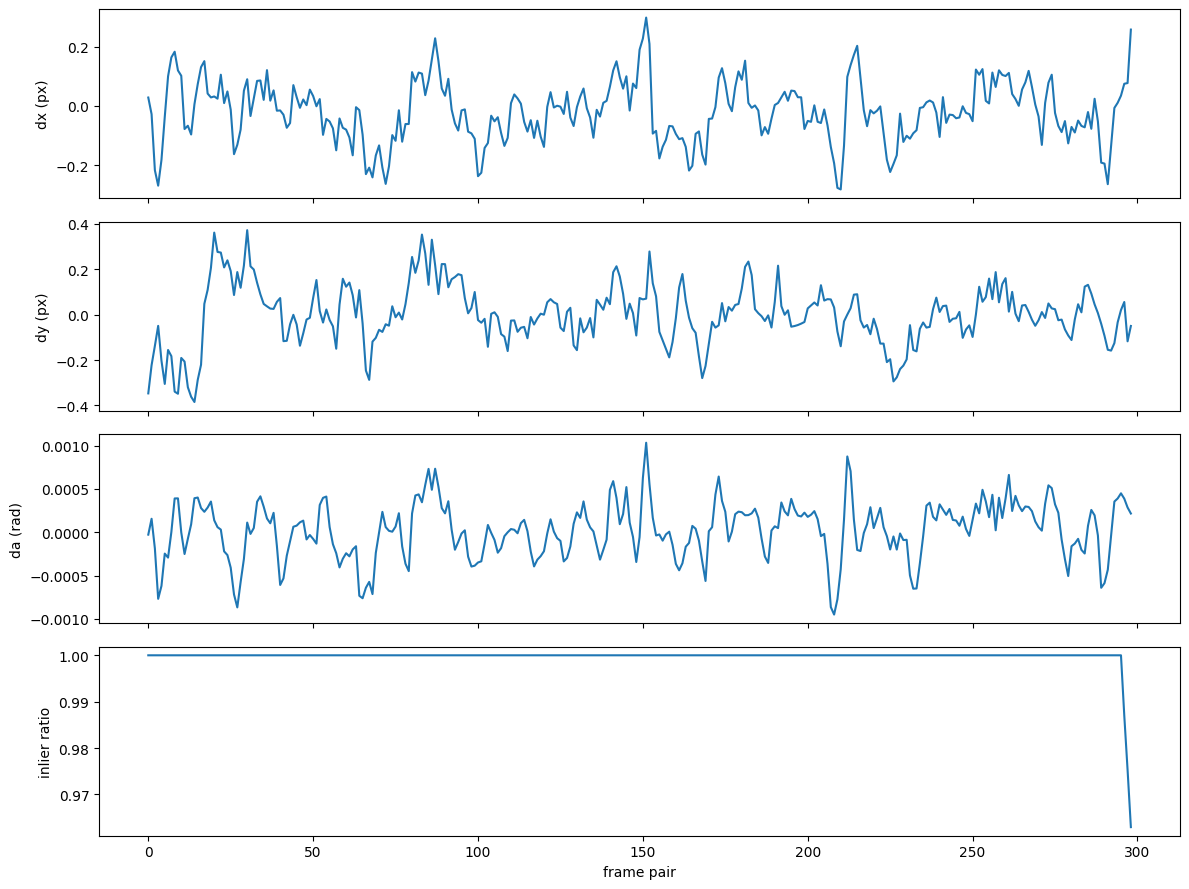

In [6]:
# Run it on the whole video
transforms = []       # one (dx, dy, da) per frame pair
inlier_ratios = []
last = (0.0, 0.0, 0.0)

prev_gray = cv2.cvtColor(frames[0], cv2.COLOR_BGR2GRAY)
for i in range(1, len(frames)):
    curr_gray = cv2.cvtColor(frames[i], cv2.COLOR_BGR2GRAY)
    res = estimate_motion(prev_gray, curr_gray)
    if res is None:                      # tracking failed: reuse previous motion
        dx, dy, da = last
        ratio = 0.0
    else:
        dx, dy, da, ratio = res
        last = (dx, dy, da)
    transforms.append((dx, dy, da))
    inlier_ratios.append(ratio)
    prev_gray = curr_gray

transforms = np.array(transforms)
inlier_ratios = np.array(inlier_ratios)
print("transforms shape:", transforms.shape)
print(f"mean inlier ratio: {inlier_ratios.mean():.2f}, min: {inlier_ratios.min():.2f}")

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for ax, data, name in zip(axes, [transforms[:, 0], transforms[:, 1], transforms[:, 2], inlier_ratios],
                          ["dx (px)", "dy (px)", "da (rad)", "inlier ratio"]):
    ax.plot(data)
    ax.set_ylabel(name)
axes[-1].set_xlabel("frame pair")
plt.tight_layout()
plt.show()

It loops over every consecutive frame pair and stores the estimated motion. If tracking fails on a pair (too few points, or RANSAC finds no model), we reuse the last good motion so the sequence doesn't break. The plots show the raw frame-to-frame motion: the jittery lines are the shake we're going to remove.

The inlier ratio is usually well above 0.7 for a static scene. Dips mean motion blur, a moving object filling the frame, or a lack of texture.

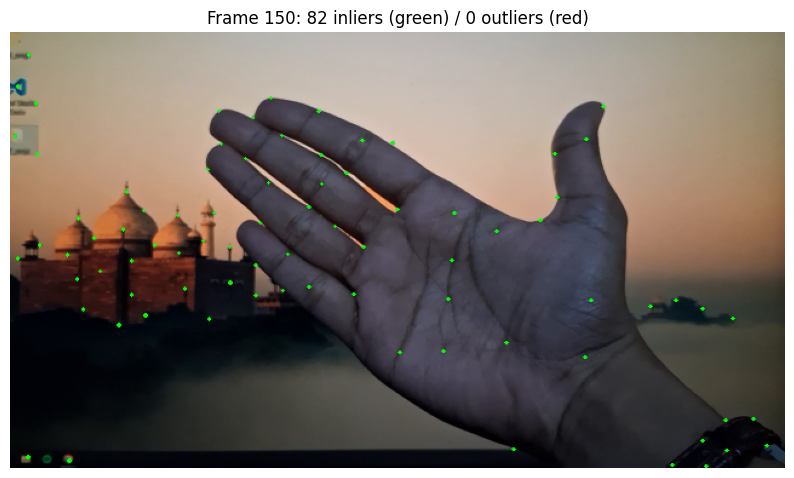

In [7]:
# checking what RANSAC rejects

i = len(frames) // 2
g0 = cv2.cvtColor(frames[i], cv2.COLOR_BGR2GRAY)
g1 = cv2.cvtColor(frames[i + 1], cv2.COLOR_BGR2GRAY)

p0 = cv2.goodFeaturesToTrack(g0, **FEATURE_PARAMS)
p1, st, _ = cv2.calcOpticalFlowPyrLK(g0, g1, p0, None, **LK_PARAMS)
ok = st.flatten() == 1
p0, p1 = p0[ok], p1[ok]

M, mask = cv2.estimateAffinePartial2D(p0, p1, method=cv2.RANSAC, ransacReprojThreshold=RANSAC_THRESH)
mask = mask.flatten().astype(bool)

vis = frames[i].copy()
for (x0, y0), (x1, y1), is_in in zip(p0.reshape(-1, 2), p1.reshape(-1, 2), mask):
    color = (0, 255, 0) if is_in else (0, 0, 255)       # green = inlier, red = outlier
    cv2.arrowedLine(vis, (int(x0), int(y0)), (int(x1), int(y1)), color, 2, tipLength=0.3)

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.title(f"Frame {i}: {mask.sum()} inliers (green) / {(~mask).sum()} outliers (red)")
plt.axis("off")
plt.show()

It repeats the estimation for a single frame pair and draws the motion of each tracked point as an arrow. Green arrows are RANSAC inliers, which agree with the global camera motion. Red arrows are outliers: badly tracked points or points on moving objects. This is the most direct way to see robust estimation working. Try changing RANSAC_THRESH (say to 1.0 and then 8.0) and watch how the green/red split changes.

In [9]:
# building camera trajectory
# transforms[i] = motion from frame i to frame i+1.
# Summing them gives the camera's accumulated position at each frame.
trajectory = np.cumsum(transforms, axis=0)   # columns: x, y, angle
print("trajectory shape:", trajectory.shape)

trajectory shape: (299, 3)


Each row in transforms is only a small frame-to-frame step. The running sum turns those steps into a path, showing where the camera "is" relative to the first frame. Shake appears as high-frequency wiggles on this path, and intentional movement (a pan, a walk) as

In [10]:
#smoothen the trajectory

def moving_average(curve, radius):
    window = 2 * radius + 1
    padded = np.pad(curve, (radius, radius), mode="edge")   # repeat edge values so the ends aren't distorted
    kernel = np.ones(window) / window
    return np.convolve(padded, kernel, mode="valid")        # same length as `curve`

def smooth(traj, radius):
    return np.stack([moving_average(traj[:, i], radius) for i in range(traj.shape[1])], axis=1)

SMOOTH_RADIUS = 30    # frames on each side (about 1 second at 30 fps)
smoothed = smooth(trajectory, SMOOTH_RADIUS)

It replaces each trajectory point with the average of its neighbors within SMOOTH_RADIUS frames on each side. That acts as a low-pass filter: fast jitter averages out, and slow motion survives. We pad the ends with their edge values so the first and last frames don't get dragged toward zero.

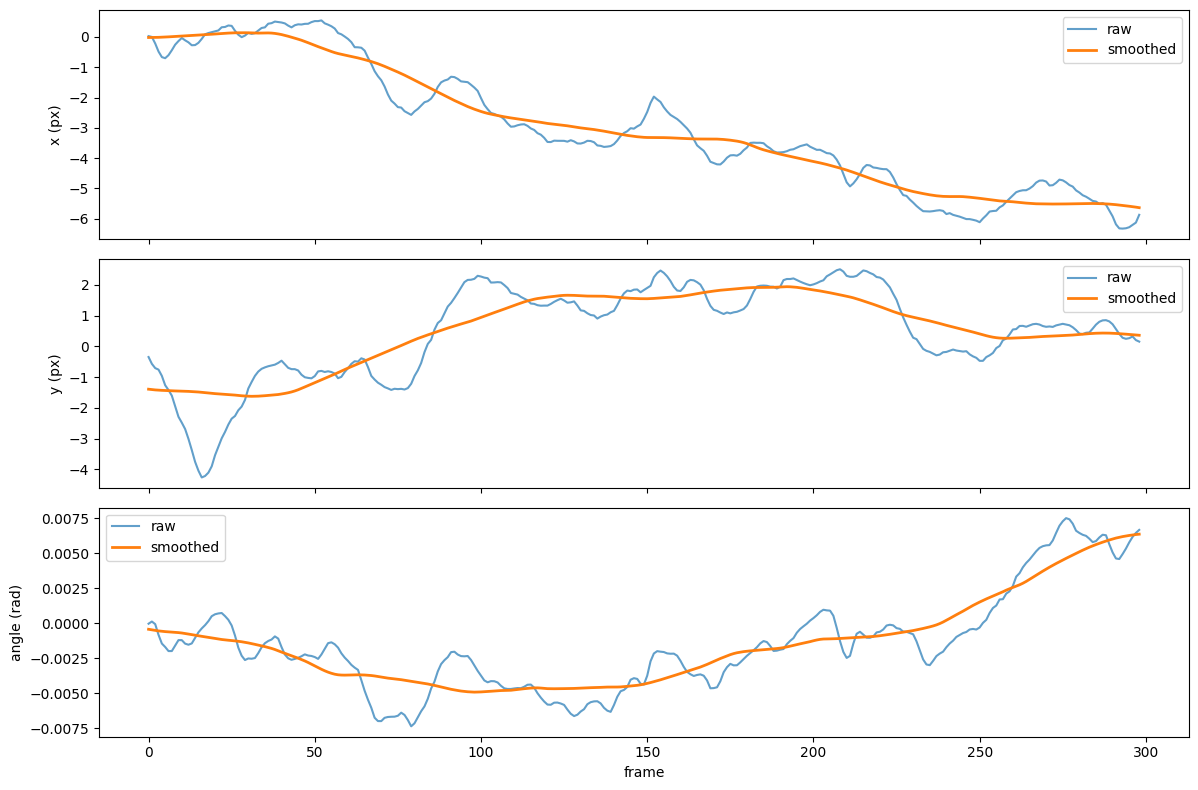

In [11]:
names = ["x (px)", "y (px)", "angle (rad)"]
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(trajectory[:, i], label="raw", alpha=0.7)
    ax.plot(smoothed[:, i], label="smoothed", linewidth=2)
    ax.set_ylabel(names[i])
    ax.legend()
axes[-1].set_xlabel("frame")
plt.tight_layout()
plt.show()

It plots the raw trajectory against the smoothed one for each motion component. The smoothed curve should follow the overall shape of the raw one but without the small wiggles. If it looks too flat or ignores real camera movement, lower SMOOTH_RADIUS; if it still looks jagged, raise it.


In [13]:
# How far must each frame be shifted/rotated so that the camera
# follows the smooth path instead of the shaky one?
corrections = smoothed - trajectory      # shape (n_frames - 1, 3)

max_shift = np.abs(corrections[:, :2]).max(axis=0)
max_angle = np.degrees(np.abs(corrections[:, 2]).max())
print(f"max correction: x={max_shift[0]:.1f}px, y={max_shift[1]:.1f}px, rotation={max_angle:.2f} deg")
print(f"frame size: {w}x{h}")

max correction: x=1.4px, y=2.8px, rotation=0.18 deg
frame size: 640x360


At each frame, the camera is at trajectory[i] but we want it at smoothed[i]. The difference is exactly how much we need to move that frame to compensate. Row i of corrections applies to frame i+1, because the first frame is our reference and stays untouched.

In [14]:
# Worst-case shift at the frame edges: translation + effect of rotation about the center
max_dx, max_dy = np.abs(corrections[:, 0]).max(), np.abs(corrections[:, 1]).max()
max_da = np.abs(corrections[:, 2]).max()

margin_x = max_dx + max_da * h / 2
margin_y = max_dy + max_da * w / 2
ZOOM = 1 + 2 * max(margin_x / w, margin_y / h) + 0.005   # small safety margin
print(f"margins: x={margin_x:.1f}px, y={margin_y:.1f}px  ->  zoom = {ZOOM:.3f}")

margins: x=1.9px, y=3.8px  ->  zoom = 1.026


When we move a frame by a few pixels, a strip of black appears on one side. If we zoom in slightly about the center and crop back to the original size, the black strips fall outside the visible area. The needed zoom depends on the largest correction we'll apply. The margin is the translation plus the rotation's effect at the frame edges (a rotation of da moves a point at distance h/2 by about da * h/2). The zoom is then 1 plus twice the margin as a fraction of the frame size, since the margin applies on both sides. For this clip it should come out around 1.02 to 1.03, which is a very mild crop.

In [15]:
#wrap every frame
def correction_matrix(dx, dy, da):
    c, s = np.cos(da), np.sin(da)
    return np.array([[c, -s, dx],
                     [s,  c, dy]], dtype=np.float32)

zoom_M = cv2.getRotationMatrix2D((w / 2, h / 2), 0, ZOOM)   # pure zoom about the center

stabilized = []
# Frame 0 is the reference: no correction, but zoom it so the crop is consistent
stabilized.append(cv2.warpAffine(frames[0], zoom_M, (w, h)))

for k in range(1, len(frames)):
    dx, dy, da = corrections[k - 1]               # correction for frame k
    M = correction_matrix(dx, dy, da)
    warped = cv2.warpAffine(frames[k], M, (w, h), borderMode=cv2.BORDER_REPLICATE)
    stabilized.append(cv2.warpAffine(warped, zoom_M, (w, h)))

print(f"stabilized {len(stabilized)} frames")

stabilized 300 frames


For each frame we build a 2x3 matrix from its correction (rotation by da, shift by dx, dy) and apply it with warpAffine. Then we apply the zoom. BORDER_REPLICATE fills any newly exposed edge pixels by copying the nearest edge pixel instead of black, as extra protection in case the zoom margin is slightly short.

Why we apply the corrections directly: trajectory[i] is how far frame i+1 has drifted from the reference, and smoothed[i] is where we want it to be. Their difference is exactly the move needed. Row k-1 of corrections belongs to frame k because the first frame has no row.


In [16]:
# side by side comparison
def label(img, text):
    out = img.copy()
    cv2.putText(out, text, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (0, 255, 255), 2, cv2.LINE_AA)
    return out

writer = cv2.VideoWriter("compare_raw.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (2 * w, h))
for orig, stab in zip(frames, stabilized):
    writer.write(np.hstack([label(orig, "original"), label(stab, "stabilized")]))
writer.release()

# Re-encode to H.264 so the browser can play it
!ffmpeg -y -loglevel error -i compare_raw.mp4 -vcodec libx264 -pix_fmt yuv420p compare.mp4
print("done")

done


It stacks each original frame next to its stabilized version, labels them, and writes a video. VideoWriter produces an mp4v file, which browsers often can't play, so the last line re-encodes it to H.264 with ffmpeg (preinstalled in Colab). The ! runs a shell command from the notebook.

In [17]:
data = b64encode(open("compare.mp4", "rb").read()).decode()
HTML(f'<video width="800" controls loop><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>')

In [18]:
def jitter(frame_list):
    steps = []
    prev = cv2.cvtColor(frame_list[0], cv2.COLOR_BGR2GRAY)
    for f in frame_list[1:]:
        cur = cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)
        res = estimate_motion(prev, cur)
        if res is not None:
            steps.append(np.hypot(res[0], res[1]))
        prev = cur
    return np.array(steps)

j_orig, j_stab = jitter(frames), jitter(stabilized)
print(f"mean frame-to-frame motion  original: {j_orig.mean():.3f} px   stabilized: {j_stab.mean():.3f} px")
print(f"max  frame-to-frame motion  original: {j_orig.max():.3f} px   stabilized: {j_stab.max():.3f} px")

mean frame-to-frame motion  original: 0.141 px   stabilized: 0.045 px
max  frame-to-frame motion  original: 0.385 px   stabilized: 1.411 px


Your eyes can miss a subtle improvement, so we measure it. We run the same motion estimator on the original and stabilized videos and compare the average and maximum frame-to-frame translation. If stabilization worked, the stabilized numbers should be clearly lower, because the high-frequency shake is gone and only the slow drift remains.